In [43]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("netflix_cleaned.csv")
df.shape



(8786, 16)

In [44]:
df["rating"].value_counts()

rating
TV-MA       3204
TV-14       2155
TV-PG        861
R            798
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

In [45]:
df["rating_group"].value_counts()

rating_group
Adults        4005
Teens         2645
Older Kids    1148
Kids           906
Not Rated       82
Name: count, dtype: int64

In [46]:
(df["rating_group"].value_counts(normalize=True) * 100).round(2)

rating_group
Adults        45.58
Teens         30.10
Older Kids    13.07
Kids          10.31
Not Rated      0.93
Name: proportion, dtype: float64

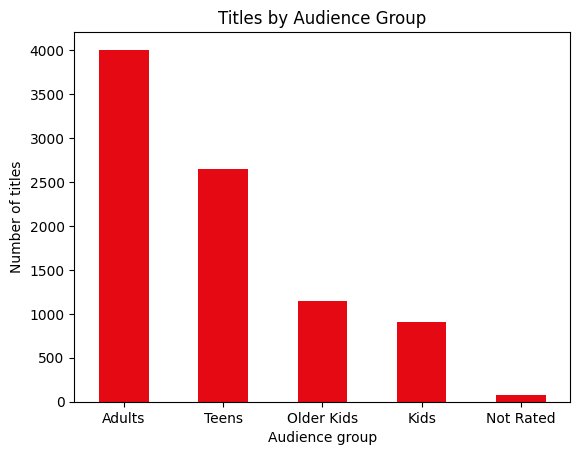

In [47]:
df["rating_group"].value_counts().plot(kind="bar", color="#E50914")
plt.title("Titles by Audience Group")
plt.xlabel("Audience group")
plt.ylabel("Number of titles")
plt.xticks(rotation=0)
plt.show()

In [48]:
df["listed_in"].head(5).tolist()

['Documentaries',
 'Crime TV Shows, International TV Shows, TV Action & Adventure',
 'TV Dramas, TV Horror, TV Mysteries',
 'Children & Family Movies, Comedies',
 'Dramas, Independent Movies, International Movies']

In [49]:
df["listed_in"].str.contains(",").sum()

np.int64(6774)

In [50]:
genres = df["listed_in"].str.split(",").explode().str.strip()
genres.shape

(19284,)

In [51]:
genres.nunique()

42

In [52]:
top_genres = genres.value_counts().head(10)
top_genres

listed_in
International Movies        2751
Dramas                      2423
Comedies                    1673
International TV Shows      1348
Documentaries                869
Action & Adventure           859
TV Dramas                    761
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

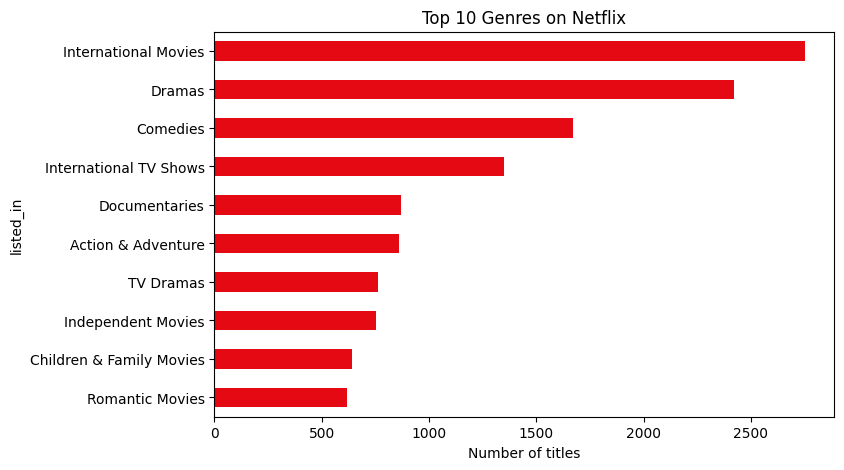

In [53]:
top_genres.sort_values().plot(kind="barh", color="#E50914", figsize=(8, 5))
plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of titles")
plt.show()

In [54]:
pd.crosstab(df["type"], df["rating_group"])

rating_group,Adults,Kids,Not Rated,Older Kids,Teens
type,,,,,
Movie,2860,442,78,827,1916
TV Show,1145,464,4,321,729


In [55]:
(pd.crosstab(df["type"], df["rating_group"], normalize="index") * 100).round(1)

rating_group,Adults,Kids,Not Rated,Older Kids,Teens
type,,,,,
Movie,46.7,7.2,1.3,13.5,31.3
TV Show,43.0,17.4,0.2,12.1,27.4


In [56]:
pd.crosstab(df["rating"], df["type"])

type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,796,2
TV-14,1426,729
TV-G,126,94
TV-MA,2061,1143


In [57]:
import plotly.express as px
print("Plotly ready")

Plotly ready


In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

df = pd.read_csv("netflix_cleaned.csv")
df.shape

(8786, 16)

In [59]:
ct = (pd.crosstab(df["type"], df["rating_group"], normalize="index") * 100).round(1).reset_index()
long = ct.melt(id_vars="type", var_name="Audience", value_name="Percent")

fig = px.bar(
    long, x="Audience", y="Percent", color="type", barmode="group", text="Percent",
    category_orders={"Audience": ["Kids", "Older Kids", "Teens", "Adults", "Not Rated"]},
    color_discrete_map={"Movie": "#E50914", "TV Show": "#221F1F"},
    title="Audience Mix: Movies vs TV Shows (% of each type)",
)
fig.show()

In [60]:
tg = genres.value_counts().head(10).reset_index()
tg.columns = ["Genre", "Titles"]

fig = px.bar(
    tg.sort_values("Titles"), x="Titles", y="Genre", orientation="h",
    color_discrete_sequence=["#E50914"], title="Top 10 Genres by Number of Titles",
)
fig.show()

In [61]:
exploded = df.assign(genre=df["listed_in"].str.split(",")).explode("genre").reset_index(drop=True)
exploded["genre"] = exploded["genre"].str.strip()
exploded.shape

(19284, 17)

In [62]:
top8 = genres.value_counts().head(8).index
sub = exploded[exploded["genre"].isin(top8)]

heat = pd.crosstab(sub["genre"], sub["rating_group"], normalize="index") * 100
heat = heat[["Kids", "Older Kids", "Teens", "Adults", "Not Rated"]].round(1)

fig = px.imshow(
    heat, text_auto=True, aspect="auto", color_continuous_scale="Reds",
    title="Audience Mix within Each Top Genre (% of the genre's titles)",
)
fig.show()

In [63]:
fig.write_html("audience_heatmap.html")

# Content Rating & Genre Analysis: Key Findings

## Overview
- Titles analyzed: 8,786 (6,123 Movies and 2,663 TV Shows)
- Ratings fall into 14 categories, grouped into 5 audience groups: Kids, Older Kids, Teens, Adults and Not Rated
- Genres: 42 different genres. 6,774 titles (77.1%) carry more than one genre, averaging about 2.2 genres per title
- Genre counts were calculated after splitting the `listed_in` column, so one title counts toward every genre it carries. Genre shares are calculated out of 8,786 titles and add up to more than 100%

## Rating Findings
1. **The catalog is aimed at older audiences.** Adults make up 45.58% of titles and Teens 30.10%, together about 76%.
2. **Children's content is about 23%.** Kids content is 10.31% and Older Kids 13.07%.
3. **Two ratings dominate.** TV-MA (3,204 titles) and TV-14 (2,155 titles) together cover about 61% of the catalog.
4. **Unrated titles are rare.** Not Rated is under 1% (82 titles).

## Movies vs TV Shows
| Audience group | Movies | TV Shows |
|---|---|---|
| Adults | 46.7% | 43.0% |
| Teens | 31.3% | 27.4% |
| Older Kids | 13.5% | 12.1% |
| Kids | 7.2% | 17.4% |
| Not Rated | 1.3% | 0.2% |

- The biggest difference is in **Kids** content: it is 17.4% of TV Shows but only 7.2% of Movies, about 2.4 times higher.
- Movies lean slightly more toward Adults and Teens.
- Ratings such as G, PG, PG-13 and NC-17 apply only to Movies.

## Genre Findings
1. **International content leads.** International Movies is the largest genre (2,751 titles, 31.3% of all titles), and International TV Shows is fourth (1,348 titles, 15.3%).
2. **Drama and comedy are core genres.** Dramas appear in 2,423 titles (27.6%) and Comedies in 1,673 (19.0%).
3. **There is a long tail.** Of the 42 genres, many are small, for example Classic & Cult TV (26 titles) and TV Shows (16 titles).

## Genre vs Audience
- **Independent Movies** is the most adult genre: 71.4% of its titles are Adults content.
- **Action & Adventure** has the highest Teens share (42.0%) among the top 8 genres.
- **Documentaries** has the largest Older Kids share (21.5%) among the top 8 genres.
- **Children & Family Movies** is almost entirely for children: 51.6% Kids and 43.7% Older Kids.

## Business Insights
- Netflix targets mainly teen and adult viewers, with children's content as a smaller but clear segment.
- TV Shows serve younger audiences more than Movies do, which suggests series are used to attract families.
- Genre choice signals the audience: Independent Movies for adults, Action & Adventure for teens, and Children & Family for kids.
- International genres rank at the top, in line with the strong presence of India and the UK in the country analysis.

## Caveats
- Ratings show the intended audience, not who actually watches.
- Grouping ratings loses detail (for example TV-14 and PG-13 both become Teens). The original `rating` column is kept.
- A title with several genres is counted in each one, so genre counts overlap.
- Percentages for small genres are based on few titles.

## Charts and Files
- Audience mix: Movies vs TV Shows (interactive bar chart)
- Top 10 genres (interactive bar chart)
- Genre by audience heatmap (interactive)